# Compare Designs across Scenarios

How accurately samples estimate a daily mean depends on the field: samples hours apart estimate a field that varies slowly better than one that varies within the hour, such as rain rates. Which field a mission will serve may not be known when it is designed. Replicates average over the sample of points, but the field is a condition under which to compare designs: a **scenario**.

It covers:

* evaluating designs in several **scenarios**;
* the front of each scenario, and how often each design is efficient;
* **regret**, and designs that are robust to the scenarios;
* **searching** for designs that do well across the scenarios.

It builds on `ExplainTradeSpace`: the objectives are fewer satellites, fewer planes, and more points accurately sampled.

## Define the Scenarios

A scenario gives other values to fixed values or uncertain parameters of the design space. The field's decorrelation time must therefore be a value of the design space, which the metrics read from each design, rather than a constant of the metrics:

* `field_space` adds the decorrelation time to the design space as a `Fixed` value (3 hours, as in `ExplainTradeSpace`);
* `sample_field` gives each design's decorrelation time to the metrics of `ExplainTradeSpace` (`sample`);
* `FIELDS` names three fields, which decorrelate within an hour, in 3 hours, and in 12 hours.

With `scenarios`, the study evaluates every design in each field, with the same samples of points, and records the field as the `scenario` of each evaluation.

In [1]:
import time
from datetime import timedelta

import pandas as pd

from trade_space_example import ACCURACY, DECORRELATION_TIME, MAX_SATELLITES, accuracy_study, describe, sample, space
from tatc.tradespace import Fixed

field_space = space.extend(decorrelation_time=Fixed(DECORRELATION_TIME))


def sample_field(observations, design):
    """The shares (%) of points sampled sufficiently and accurately (of its field)."""
    return sample(observations, design.decorrelation_time)


FIELDS = {
    "1 hour": {"decorrelation_time": timedelta(hours=1)},
    "3 hours": {},  # the fixed value
    "12 hours": {"decorrelation_time": timedelta(hours=12)},
}
field_study = accuracy_study.replace(space=field_space, metrics=sample_field, scenarios=FIELDS)
began = time.perf_counter()
fields = field_study.run()  # every design of the design space, in each field
print(f"{len(fields)} evaluations in {time.perf_counter() - began:.0f} s")

16440 evaluations in 1 s


## Compare the Fronts of the Scenarios

Criteria `by` the scenario judge designs in each field: `aggregate` summarizes each design in each field, and `pareto_front` finds the front of each field. `robustness` gives the share of the fields in which each design is efficient (its **Pareto trace**). The table gives the designs efficient in more than half of the fields:

In [2]:
from tatc.tradespace import Criteria, aggregate, pareto_front, robustness

BY_FIELD = Criteria(ACCURACY, by="scenario")
by_field = aggregate(fields, BY_FIELD)
by_field["pareto"] = pareto_front(by_field, BY_FIELD)
print("efficient designs:", by_field[by_field.pareto].scenario.value_counts()[list(FIELDS)].to_dict())

# a row per design: its share accurately sampled in each field, and the share of the fields in which it is efficient
values = by_field.drop_duplicates("design").set_index("design")  # the values of each design
traced = pd.DataFrame(
    {"description": values.apply(describe, axis=1), "satellites": values.satellites, "planes": values.planes}
)
traced = traced.join(by_field.pivot(index="design", columns="scenario", values="accurate")[list(FIELDS)])
traced["pareto_trace"] = robustness(fields, ACCURACY).set_index("design")["pareto_trace"]
traced[traced.pareto_trace > 0.5].sort_values(["satellites", "planes"]).round(2)

efficient designs: {'1 hour': 14, '3 hours': 13, '12 hours': 6}


,description,satellites,planes,1 hour,3 hours,12 hours,pareto_trace
design,,,,,,,
33b006848799,"800 km, 60 deg FOR, Walker 45 deg: 2 x 1 (spac...",2.0,2.0,26.2,34.2,60.4,0.67
b85daf65c3a4,"800 km, 60 deg FOR, Walker 75 deg: 1 x 3 (spac...",3.0,1.0,8.0,17.0,95.6,0.67
c576e2e2dbd1,"800 km, 60 deg FOR, SSO: 2 at 15:00, 1 at 09:00",3.0,2.0,40.8,60.6,85.8,0.67
3690f1194419,"800 km, 60 deg FOR, SSO: 2 at 15:00, 2 at 09:00",4.0,2.0,69.0,85.4,93.0,0.67
cb6bd361b577,"800 km, 60 deg FOR, Walker 75 deg: 4 x 2 (spac...",8.0,4.0,96.6,96.6,97.8,0.67
5529c21520be,"800 km, 60 deg FOR, Walker 75 deg: 3 x 3 (spac...",9.0,3.0,97.8,97.8,97.8,0.67
de505bc89299,"800 km, 60 deg FOR, Walker 75 deg: 3 x 3 (spac...",9.0,3.0,97.8,97.8,97.8,0.67
679ca275c8fc,"800 km, 60 deg FOR, Walker 75 deg: 3 x 3 (spac...",9.0,3.0,97.8,97.8,97.8,0.67


Every design in each field, by its layout, with the front of each field ringed:

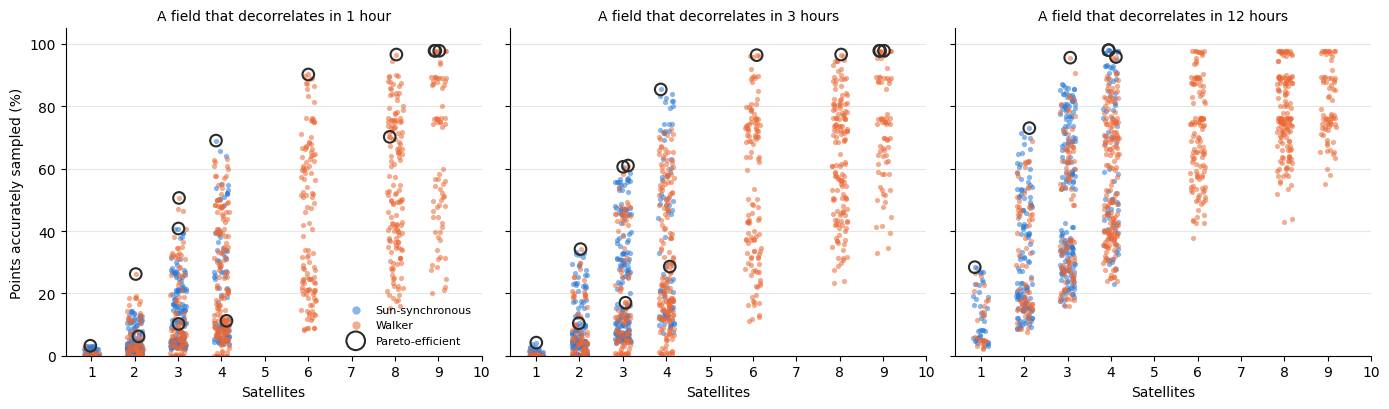

In [3]:
import matplotlib.pyplot as plt

from tatc.tradespace import plot_designs

LAYOUTS = {"walker": "Walker", "sso": "Sun-synchronous"}
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True)
for ax, field in zip(axes, FIELDS):
    plot_designs(
        by_field[by_field.scenario == field],
        "satellites",
        "accurate",
        by="layout",
        front="pareto",
        names=LAYOUTS,
        jitter=0.18,  # spreads the designs of each number of satellites, for legibility
        legend="lower right" if ax is axes[0] else None,
        ax=ax,
    )
    ax.set(xlabel="Satellites", ylabel="", xticks=range(1, MAX_SATELLITES + 1), ylim=(0, 105))
    ax.set_title(f"A field that decorrelates in {field}", fontsize=10)
axes[0].set_ylabel("Points accurately sampled (%)")
fig.tight_layout()
plt.show()

Which designs are efficient depends on the field: 14 designs in the field of 1 hour, 13 in that of 3 hours, and 6 in that of 12 hours, and no design is efficient in all three. In the field of 12 hours, one plane samples well: three satellites in one plane sample 96% of the points accurately. In the fields that vary within hours, the samples must spread over the day: the same three satellites sample 17% (3 hours) and 8% (1 hour), against 61% and 41% for three satellites in two sun-synchronous planes.

## Choose a Robust Design

A design need not be efficient in any field to be a good choice when the field is unknown. Its **regret** in a field is how far it falls behind the best design there, and a **robust** design has the least regret in its worst field.

Regret here is in one objective, the share accurately sampled, among the designs of at most a number of satellites (a `Requirement`). With the numbers of satellites and planes as objectives too, a design could match the cheapest efficient design by dropping satellites, and regret would mostly count satellites.

In [4]:
from tatc.tradespace import Requirement

robust, robust_design = [], {}
for limit in (2, 3, 4, 6):
    within = Criteria({"accurate": "max"}, requirements=[Requirement("satellites", "<=", limit)])
    regret = robustness(fields, within).set_index("design")
    best = robust_design[limit] = regret["max_regret"].idxmin()  # the design of least regret in its worst field
    robust.append(
        {
            "at most": limit,
            **traced.loc[best, ["description", "satellites", "planes"]],
            **regret.loc[best].drop("pareto_trace"),
        }
    )
pd.DataFrame(robust).set_index("at most").round(1)

,description,satellites,planes,max_regret,1 hour regret,3 hours regret,12 hours regret
at most,,,,,,,
2,"800 km, 60 deg FOR, Walker 75 deg: 2 x 1 (spac...",2.0,2.0,11.0,7.6,6.4,11.0
3,"800 km, 60 deg FOR, SSO: 2 at 15:00, 1 at 09:00",3.0,2.0,9.8,9.8,0.4,9.8
4,"800 km, 60 deg FOR, SSO: 2 at 15:00, 2 at 09:00",4.0,2.0,5.0,0.0,0.0,5.0
6,"700 km, 60 deg FOR, Walker 75 deg: 3 x 2 (spac...",6.0,3.0,0.4,0.4,0.2,0.4


In each field, the robust design of each number of satellites (blue) against the best design of at most as many satellites in that field (gray): the gap between them is the robust design's regret in the field.

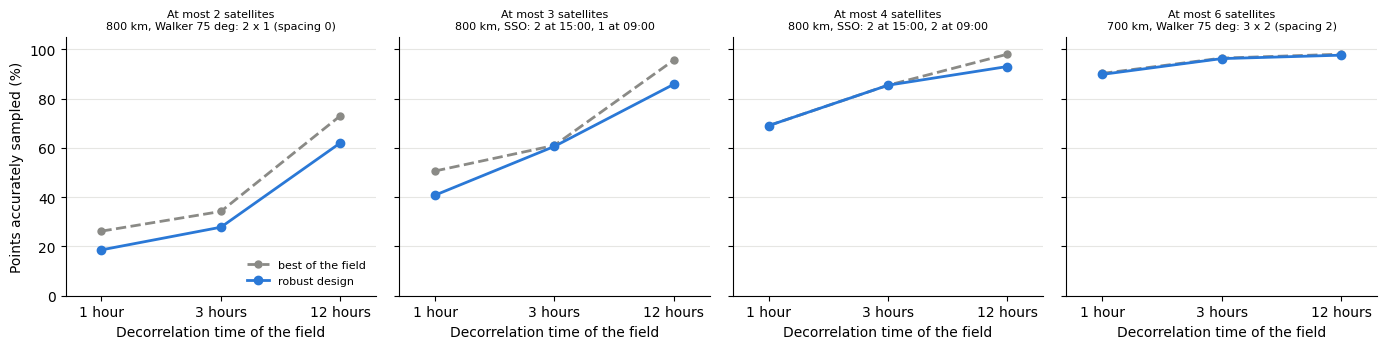

In [5]:
from tatc.tradespace import style_axes
from tatc.tradespace.plotting import COLORS, GRAY

fig, axes = plt.subplots(1, len(robust_design), figsize=(14, 3.6), sharey=True)
for ax, (limit, best) in zip(axes, robust_design.items()):
    within = by_field[by_field.satellites <= limit]
    ceiling = within.groupby("scenario")["accurate"].max()[list(FIELDS)]
    ax.plot(range(len(FIELDS)), ceiling, color=GRAY, lw=2, ls="--", marker="o", ms=5, label="best of the field")
    ax.plot(
        range(len(FIELDS)),
        traced.loc[best, list(FIELDS)],
        color=COLORS[0],
        lw=2,
        marker="o",
        ms=6,
        label="robust design",
    )
    ax.set_xticks(range(len(FIELDS)), list(FIELDS))
    ax.set(xlabel="Decorrelation time of the field", ylim=(0, 105), xlim=(-0.3, len(FIELDS) - 0.7))
    ax.set_title(
        f"At most {limit} satellites\n{traced.loc[best, 'description'].replace(', 60 deg FOR', '')}", fontsize=8
    )
    style_axes(ax)
axes[0].set_ylabel("Points accurately sampled (%)")
axes[0].legend(loc="lower right", fontsize=8, frameon=False)
fig.tight_layout()
plt.show()

The robust choice depends on how many satellites the mission can afford. Four satellites in two sun-synchronous planes, crossing the equator at 09:00 and 15:00, are the best in the fields of 1 and 3 hours, and fall 5 points behind the best in the field of 12 hours: a mission that does not know its field loses little by choosing them. Two or three satellites fall 10 or 11 points behind somewhere. Six satellites in three Walker planes (at 700 km) fall at most 0.4 points behind the best in any field, though they are efficient in none: a robust design need not be the best in any scenario. Regrets of a point or two are within the sampling error of the means of five replicates.

## Search for Robust Designs

A search needs one value of each objective for each design, not one for each field. Criteria `across` the fields (`Across`) combine the statistics of each design over the fields: by their mean (`rule="mean"`), or by their worst (`rule="worst"`).

Here, pymoo searches for the designs most accurate on average over the three fields, with as many proposals as in `SearchTradeSpace`. It evaluates each design that it proposes in every field. Every design was evaluated above, so the results come from the store, and the search can be compared with the true front of the mean.

In [6]:
from pymoo.algorithms.moo.nsga2 import NSGA2

from tatc.tradespace import Across, hypervolume, hypervolume_progress, optimize_pymoo

FIELD_MEAN = Criteria(ACCURACY, across=Across(rule="mean"))
REFERENCE = {"satellites": MAX_SATELLITES + 1, "planes": 5, "accurate": 0}  # worse than every design
mean_summary = aggregate(fields, FIELD_MEAN)
true_front = set(mean_summary.design[pareto_front(mean_summary, FIELD_MEAN)])
true_hypervolume = hypervolume(mean_summary, FIELD_MEAN, REFERENCE)

search = optimize_pymoo(field_study, FIELD_MEAN, NSGA2(pop_size=20), ("n_gen", 10), seed=1)  # 200 proposals
found = 100 * hypervolume_progress(search.results, FIELD_MEAN, REFERENCE).iloc[-1] / true_hypervolume
evaluated = set(search.results.design)
print(
    f"{len(evaluated)} designs evaluated (in {len(FIELDS)} fields each): {found:.1f}% of the hypervolume of the true "
    f"front, and {len(evaluated & true_front)} of its {len(true_front)} designs"
)
print("the field in which each design is least accurate:", traced[list(FIELDS)].idxmin(axis=1).value_counts().to_dict())

147 designs evaluated (in 3 fields each): 99.3% of the hypervolume of the true front, and 8 of its 12 designs
the field in which each design is least accurate: {'1 hour': 1028, '3 hours': 68}


The search finds 99.3% of the hypervolume of the true front of the mean with 147 designs, and 8 of its 12 designs. Each design costs three times as much as in a search of one field, as it is evaluated in each field.

A worst case (`rule="worst"`) suits scenarios that are hardest for different designs. Here, the field that varies within an hour is the hardest for 1,028 of the 1,096 designs, so a search by the worst would mostly search that field alone.

## Summary

* The `scenarios` of a study compare designs under conditions rather than averaging over them. A scenario sets values of the design space (here, a `Fixed` decorrelation time of the field), and the study evaluates each design in each scenario, with the same replicates.
* Criteria `by` the scenario give the front of each scenario, and `robustness` the share of the scenarios in which each design is efficient (its Pareto trace) and its regret in each. The design of least maximum regret is a robust choice, whether or not it is efficient in any scenario.
* Criteria `across` the scenarios (`Across`) judge each design once, by its mean or its worst over them, as a search for robust designs needs.

The next notebook, `TradeCostAndUtility`, replaces the numbers of satellites and planes with costs.